# Predicting Heart Disease

A binary classification problem on the UCI Heart Failure Prediction dataset: given a patient's demographics, resting measurements and exercise test results, predict whether heart disease is present.

**Dataset:** `heart_disease_prediction.csv`, 918 patients, 11 predictors and a binary `HeartDisease` target. The predictors mix clinical measurements (resting blood pressure, cholesterol, maximum heart rate, ST depression) with categorical findings (chest pain type, resting ECG result, exercise-induced angina, ST slope).

**Why recall matters more than accuracy here.** A false negative is a patient with heart disease sent home. A false positive is a patient sent for further testing they did not need. These are not symmetric costs, so the model is tuned for recall on the positive class and accuracy is reported as context rather than as the objective. This single decision changes which model wins, as section 8 shows.

**Approach:**
1. Load, profile, and check quality, which turns up a problem the column summaries hide.
2. Explore each predictor against the target.
3. Handle physiologically impossible values correctly, which is the most consequential decision in the notebook.
4. Encode, then split with stratification.
5. Build a leak-free pipeline so imputation and scaling are fitted on training folds only.
6. Tune K-nearest neighbours with cross-validated grid search, scored on recall.
7. Compare against logistic regression and a random forest on the same split.
8. Tune the decision threshold, and be explicit about what is being traded away.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('pandas     ', pd.__version__)
print('numpy      ', np.__version__)
print('scikit-learn', sklearn.__version__)

pandas      2.2.2
numpy       2.0.1
scikit-learn 1.5.1


## 1. Load and profile

In [2]:
heart = pd.read_csv('heart_disease_prediction.csv')
print('Shape:', heart.shape)
heart.head()

Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
heart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [4]:
heart.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


In [5]:
print('Missing values per column (pandas view):')
print(heart.isnull().sum())
print()
print('Duplicate rows:', heart.duplicated().sum())

Missing values per column (pandas view):
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Duplicate rows: 0


`isnull()` reports zero missing values in every column. That is the kind of clean bill of health worth distrusting, and section 3 explains why.

## 2. Exploring the predictors against the target

In [6]:
counts = heart['HeartDisease'].value_counts().sort_index()
print('Target balance:')
for v in counts.index:
    label = 'Heart disease' if v == 1 else 'No heart disease'
    print('  ' + str(v) + ' (' + label + '): ' + str(counts[v]) + '  (' + str(round(100 * counts[v] / len(heart), 1)) + '%)')
print()
print('Majority-class baseline accuracy:', round(counts.max() / len(heart), 4))

Target balance:
  0 (No heart disease): 410  (44.7%)
  1 (Heart disease): 508  (55.3%)

Majority-class baseline accuracy: 0.5534


In [7]:
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

for col in cat_cols:
    rate = heart.groupby(col)['HeartDisease'].agg(['mean', 'count'])
    rate.columns = ['heart_disease_rate', 'n']
    rate['heart_disease_rate'] = rate['heart_disease_rate'].round(3)
    print(col)
    print(rate)
    print()

Sex
     heart_disease_rate    n
Sex                         
F                 0.259  193
M                 0.632  725

ChestPainType
               heart_disease_rate    n
ChestPainType                         
ASY                         0.790  496
ATA                         0.139  173
NAP                         0.355  203
TA                          0.435   46

FastingBS
           heart_disease_rate    n
FastingBS                         
0                       0.480  704
1                       0.794  214

RestingECG
            heart_disease_rate    n
RestingECG                         
LVH                      0.564  188
Normal                   0.516  552
ST                       0.657  178

ExerciseAngina
                heart_disease_rate    n
ExerciseAngina                         
N                            0.351  547
Y                            0.852  371

ST_Slope
          heart_disease_rate    n
ST_Slope                         
Down                   0.778   63


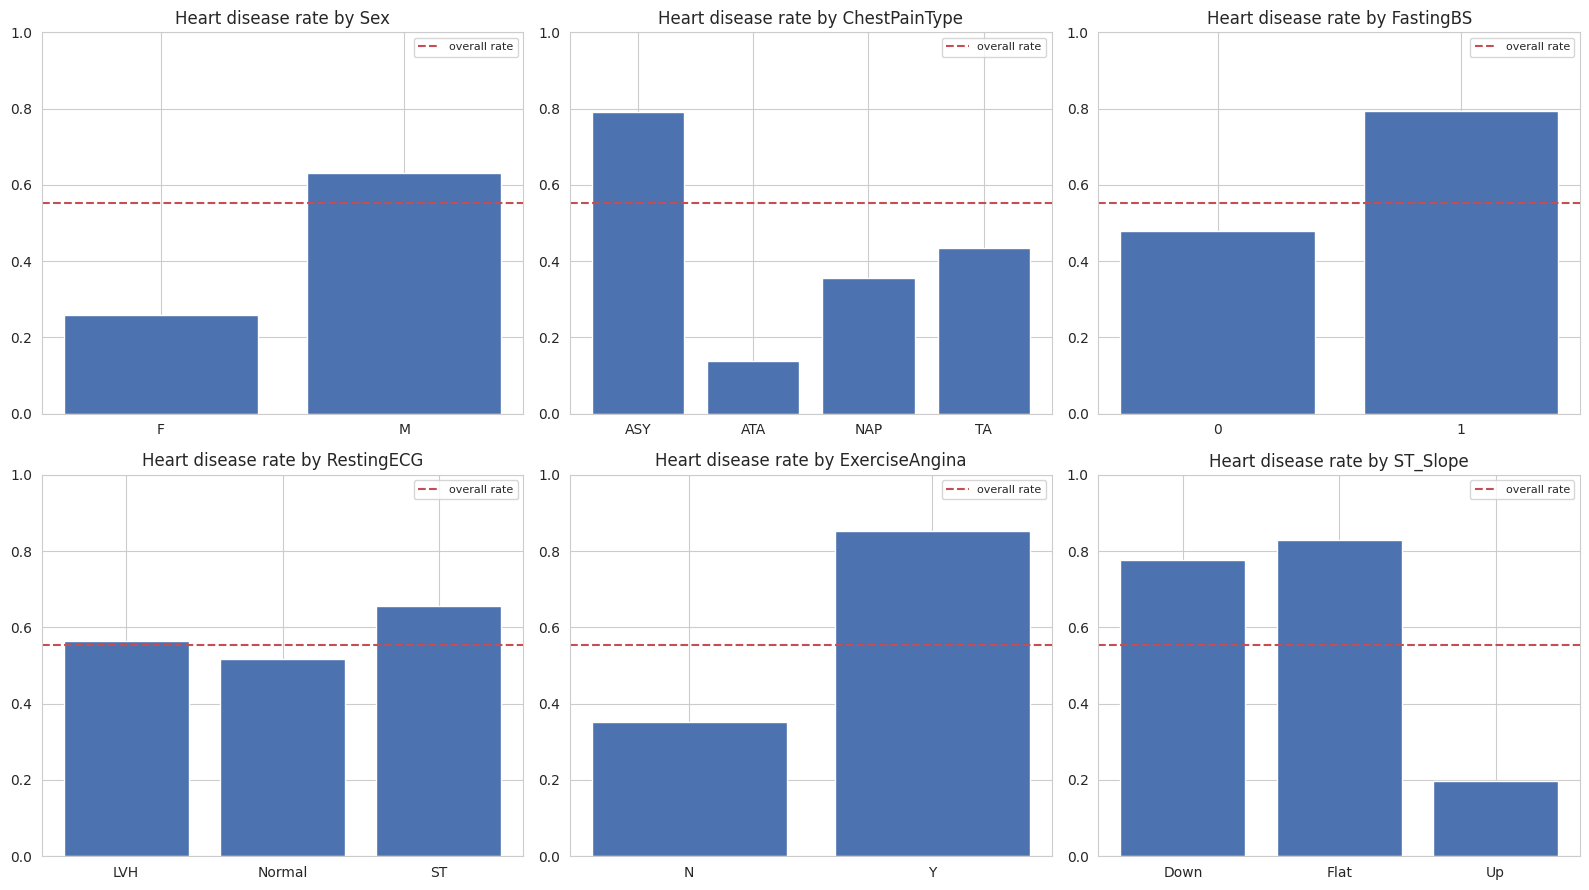

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), cat_cols):
    rate = heart.groupby(col)['HeartDisease'].mean()
    ax.bar([str(i) for i in rate.index], rate.values, color='#4C72B0')
    ax.axhline(heart['HeartDisease'].mean(), color='#C44E52', linestyle='--', label='overall rate')
    ax.set_ylim(0, 1)
    ax.set_title('Heart disease rate by ' + col)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

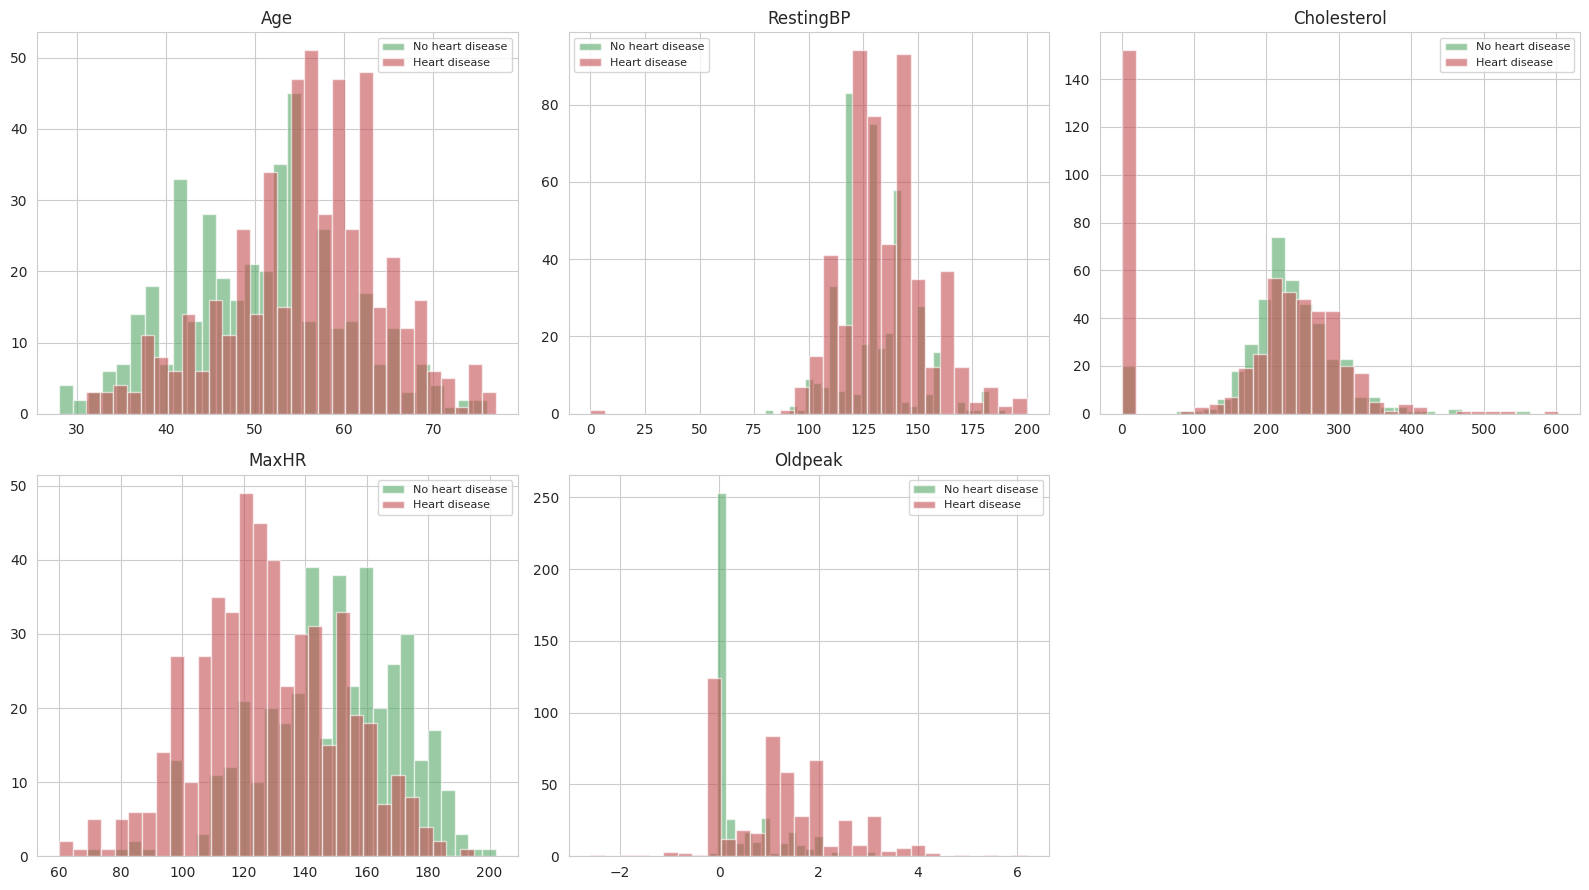

In [9]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), num_cols):
    for target, colour, label in [(0, '#55A868', 'No heart disease'), (1, '#C44E52', 'Heart disease')]:
        ax.hist(heart.loc[heart['HeartDisease'] == target, col], bins=30, alpha=0.6, color=colour, label=label)
    ax.set_title(col)
    ax.legend(fontsize=8)
axes.flatten()[-1].set_visible(False)
plt.tight_layout()
plt.show()

## 3. The problem the column summaries hide

Look at the `describe()` output again. `Cholesterol` has a minimum of 0 and `RestingBP` has a minimum of 0. Neither is physiologically possible in a living patient: serum cholesterol of 0 mg/dL and a resting blood pressure of 0 mmHg both mean the measurement is absent, recorded as a zero instead of as a null.

This is why `isnull()` returned a clean sheet. The missing data is disguised as valid data, and left alone it is fed straight into the distance metric, where a patient with no cholesterol reading looks like the healthiest patient in the dataset.

In [10]:
for col in ['Cholesterol', 'RestingBP']:
    n = int((heart[col] == 0).sum())
    print(col + ': ' + str(n) + ' zero values (' + str(round(100 * n / len(heart), 1)) + '% of rows)')
print()
print('Cholesterol percentiles among non-zero records:')
print(heart.loc[heart['Cholesterol'] > 0, 'Cholesterol'].describe().round(1))

Cholesterol: 172 zero values (18.7% of rows)
RestingBP: 1 zero values (0.1% of rows)

Cholesterol percentiles among non-zero records:
count    746.0
mean     244.6
std       59.2
min       85.0
25%      207.2
50%      237.0
75%      275.0
max      603.0
Name: Cholesterol, dtype: float64


### The missingness is not random, and that matters

The obvious responses are to drop those rows or to impute them and move on. Both would be mistakes, because whether a cholesterol reading exists at all turns out to carry information about the target. The crosstab below is the evidence. Dropping the rows would discard roughly a fifth of the dataset along with a strong signal; imputing them silently would bury that signal in the median.

The approach taken instead is to do both things explicitly: replace the impossible zeros with `NaN` so they are imputed honestly inside the pipeline, **and** keep a binary `CholesterolMissing` flag so the model can still use the fact of the absence. Missingness becomes a feature rather than a contaminant.

In [11]:
chol_missing = (heart['Cholesterol'] == 0).astype(int)

print('Heart disease rate where Cholesterol is recorded as 0:', round(heart.loc[chol_missing == 1, 'HeartDisease'].mean(), 4))
print('Heart disease rate where Cholesterol is present:      ', round(heart.loc[chol_missing == 0, 'HeartDisease'].mean(), 4))
print('Overall heart disease rate:                           ', round(heart['HeartDisease'].mean(), 4))
print()
ct = pd.crosstab(chol_missing, heart['HeartDisease'])
ct.index = ['Cholesterol present', 'Cholesterol missing (0)']
ct.columns = ['No heart disease', 'Heart disease']
print(ct)

Heart disease rate where Cholesterol is recorded as 0: 0.8837
Heart disease rate where Cholesterol is present:       0.4772
Overall heart disease rate:                            0.5534

                         No heart disease  Heart disease
Cholesterol present                   390            356
Cholesterol missing (0)                20            152


## 4. Preparing the feature matrix

One-hot encoding is applied with `get_dummies` before the split. This is safe because the encoding of a row depends only on that row, so no information crosses from test to train. Imputation and scaling are the opposite case, since both compute statistics across rows, and those are therefore deferred into the pipeline in section 5 rather than applied here.

In [12]:
df = heart.copy()

# Preserve the fact of the missing measurement, then mark it missing honestly
df['CholesterolMissing'] = (df['Cholesterol'] == 0).astype(int)
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)
df['RestingBP'] = df['RestingBP'].replace(0, np.nan)

print('NaNs now visible to the imputer:')
print(df[['Cholesterol', 'RestingBP']].isnull().sum())

y = df['HeartDisease']
X = pd.get_dummies(df.drop(columns=['HeartDisease']),
                   columns=['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope'],
                   drop_first=True)
X = X.astype(float)

print()
print('Feature matrix:', X.shape)
print(X.columns.tolist())

NaNs now visible to the imputer:
Cholesterol    172
RestingBP        1
dtype: int64

Feature matrix: (918, 16)
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'CholesterolMissing', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, ' positive rate', round(y_train.mean(), 4))
print('Test: ', X_test.shape, '  positive rate', round(y_test.mean(), 4))
print()
print('Stratification held the class balance steady across the split.')

Train: (734, 16)  positive rate 0.5531
Test:  (184, 16)   positive rate 0.5543

Stratification held the class balance steady across the split.


## 5. A leak-free pipeline

Imputing the median or fitting the scaler on the full dataset before splitting is the most common silent mistake in a notebook like this. It leaks test-set information into training and inflates every score that follows, usually by a small enough margin that nothing looks wrong.

Wrapping the imputer, the scaler and the estimator in a `Pipeline` makes the leak impossible. During cross-validation the pipeline is refitted on each training fold, so the median and the scaling parameters are recomputed from that fold alone. Scaling is not optional for K-nearest neighbours: it works on Euclidean distance, and unscaled cholesterol in mg/dL would dominate `Oldpeak` entirely.

In [14]:
def make_pipeline(model):
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', model)
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

knn_default = make_pipeline(KNeighborsClassifier())
scores = cross_val_score(knn_default, X_train, y_train, cv=cv, scoring='recall')
print('Untuned KNN (k=5), 5-fold CV recall:', np.round(scores, 4))
print('Mean recall:', round(scores.mean(), 4), '+/-', round(scores.std(), 4))

Untuned KNN (k=5), 5-fold CV recall: [0.8902 0.8765 0.8395 0.8765 0.9259]
Mean recall: 0.8818 +/- 0.0278


## 6. Tuning K-nearest neighbours

The grid covers the number of neighbours, whether neighbours are weighted by distance, and the distance metric itself (`p=1` is Manhattan, `p=2` is Euclidean). Scoring is recall, for the clinical reason given at the top. `refit` therefore selects the configuration that misses the fewest sick patients, not the one with the prettiest accuracy.

In [15]:
param_grid = {
    'model__n_neighbors': list(range(1, 32, 2)),
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}

grid = GridSearchCV(make_pipeline(KNeighborsClassifier()), param_grid,
                    cv=cv, scoring='recall', n_jobs=-1, return_train_score=False)
grid.fit(X_train, y_train)

print('Configurations evaluated:', len(grid.cv_results_['params']))
print('Best cross-validated recall:', round(grid.best_score_, 4))
print('Best parameters:', grid.best_params_)

Configurations evaluated: 64
Best cross-validated recall: 0.9163
Best parameters: {'model__n_neighbors': 17, 'model__p': 1, 'model__weights': 'distance'}


/usr/local/lib/python3.11/dist-packages/numpy/ma/core.py:2846: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


In [16]:
res = pd.DataFrame(grid.cv_results_)[['param_model__n_neighbors', 'param_model__weights',
                                      'param_model__p', 'mean_test_score', 'std_test_score']]
res.columns = ['k', 'weights', 'p', 'mean_cv_recall', 'std']
print('Top 10 configurations by cross-validated recall:')
print(res.sort_values('mean_cv_recall', ascending=False).head(10).round(4).to_string(index=False))

Top 10 configurations by cross-validated recall:
 k  weights  p  mean_cv_recall    std
17 distance  1          0.9163 0.0194
 9  uniform  1          0.9139 0.0345
15  uniform  1          0.9139 0.0203
15 distance  1          0.9139 0.0203
 7  uniform  1          0.9114 0.0339
 9 distance  1          0.9114 0.0323
11  uniform  1          0.9114 0.0248
13 distance  1          0.9114 0.0210
27 distance  1          0.9114 0.0160
 7 distance  1          0.9090 0.0367


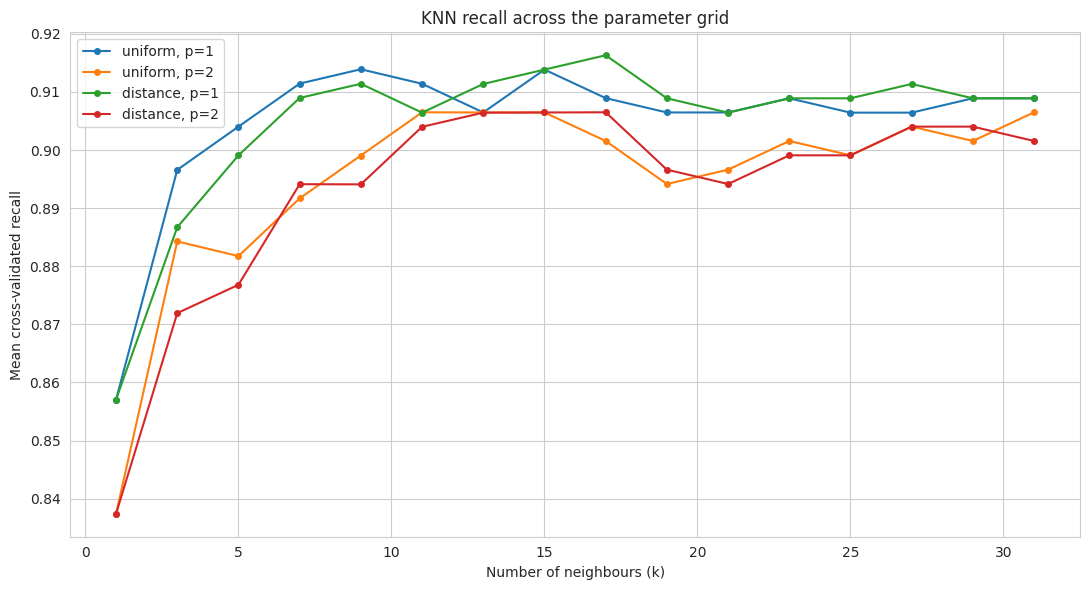

In [17]:
fig, ax = plt.subplots(figsize=(11, 6))
for w in ['uniform', 'distance']:
    for p in [1, 2]:
        sub = res[(res['weights'] == w) & (res['p'] == p)].sort_values('k')
        ax.plot(sub['k'], sub['mean_cv_recall'], marker='o', markersize=4,
                label=w + ', p=' + str(p))
ax.set_xlabel('Number of neighbours (k)')
ax.set_ylabel('Mean cross-validated recall')
ax.set_title('KNN recall across the parameter grid')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Evaluating on the held-out test set

The test set has been untouched until this point. Every number below is computed once, on data that played no part in imputation, scaling, parameter selection or model fitting.

In [18]:
best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test)
y_proba = best_knn.predict_proba(X_test)[:, 1]

print('Accuracy :', round(accuracy_score(y_test, y_pred), 4))
print('Precision:', round(precision_score(y_test, y_pred), 4))
print('Recall   :', round(recall_score(y_test, y_pred), 4))
print('F1       :', round(f1_score(y_test, y_pred), 4))
print('ROC AUC  :', round(roc_auc_score(y_test, y_proba), 4))
print()
print('Majority-class baseline accuracy:', round(max(y_test.mean(), 1 - y_test.mean()), 4))

Accuracy : 0.9076
Precision: 0.9126
Recall   : 0.9216
F1       : 0.9171
ROC AUC  : 0.9449

Majority-class baseline accuracy: 0.5543


In [19]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print('Confusion matrix:')
print(pd.DataFrame(cm,
                   index=['Actual: no disease', 'Actual: disease'],
                   columns=['Predicted: no disease', 'Predicted: disease']))
print()
print('True negatives :', tn)
print('False positives:', fp, '(sent for unnecessary further testing)')
print('False negatives:', fn, '(sick patients sent home, the costly error)')
print('True positives :', tp)
print()
print(classification_report(y_test, y_pred, target_names=['No heart disease', 'Heart disease']))

Confusion matrix:
                    Predicted: no disease  Predicted: disease
Actual: no disease                     73                   9
Actual: disease                         8                  94

True negatives : 73
False positives: 9 (sent for unnecessary further testing)
False negatives: 8 (sick patients sent home, the costly error)
True positives : 94

                  precision    recall  f1-score   support

No heart disease       0.90      0.89      0.90        82
   Heart disease       0.91      0.92      0.92       102

        accuracy                           0.91       184
       macro avg       0.91      0.91      0.91       184
    weighted avg       0.91      0.91      0.91       184



## 8. Comparing against other classifiers

KNN was the assigned model, but a single model with no comparison tells you nothing about whether it was a reasonable choice. Logistic regression and a random forest are fitted through the identical pipeline on the identical split, so the comparison is fair.

In [20]:
candidates = {
    'KNN (tuned)': best_knn,
    'Logistic regression': make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    'Random forest': make_pipeline(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))
}

rows = []
curves = {}
for name, model in candidates.items():
    if name != 'KNN (tuned)':
        model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    cmx = confusion_matrix(y_test, pred)
    rows.append({
        'model': name,
        'accuracy': round(accuracy_score(y_test, pred), 4),
        'precision': round(precision_score(y_test, pred), 4),
        'recall': round(recall_score(y_test, pred), 4),
        'f1': round(f1_score(y_test, pred), 4),
        'roc_auc': round(roc_auc_score(y_test, proba), 4),
        'false_negatives': int(cmx[1, 0])
    })
    curves[name] = roc_curve(y_test, proba)

comparison = pd.DataFrame(rows).set_index('model')
print(comparison.to_string())

                     accuracy  precision  recall      f1  roc_auc  false_negatives
model                                                                             
KNN (tuned)            0.9076     0.9126  0.9216  0.9171   0.9449                8
Logistic regression    0.8913     0.8868  0.9216  0.9038   0.9327                8
Random forest          0.8804     0.8846  0.9020  0.8932   0.9371               10


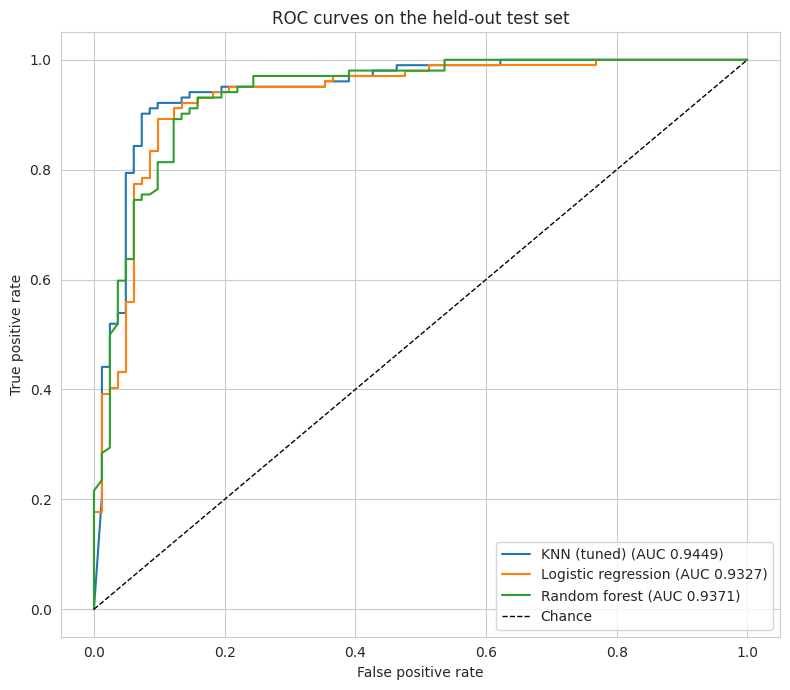

In [21]:
plt.figure(figsize=(8, 7))
for name, (fpr, tpr, _) in curves.items():
    auc = comparison.loc[name, 'roc_auc']
    plt.plot(fpr, tpr, label=name + ' (AUC ' + str(auc) + ')')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves on the held-out test set')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Random forest feature importances:
ST_Slope_Up           0.1640
ST_Slope_Flat         0.1199
Oldpeak               0.1139
MaxHR                 0.1031
ExerciseAngina_Y      0.0850
Age                   0.0766
Cholesterol           0.0732
RestingBP             0.0704
CholesterolMissing    0.0409
ChestPainType_ATA     0.0350
Sex_M                 0.0343
ChestPainType_NAP     0.0284
FastingBS             0.0222
RestingECG_Normal     0.0144
ChestPainType_TA      0.0100
RestingECG_ST         0.0089


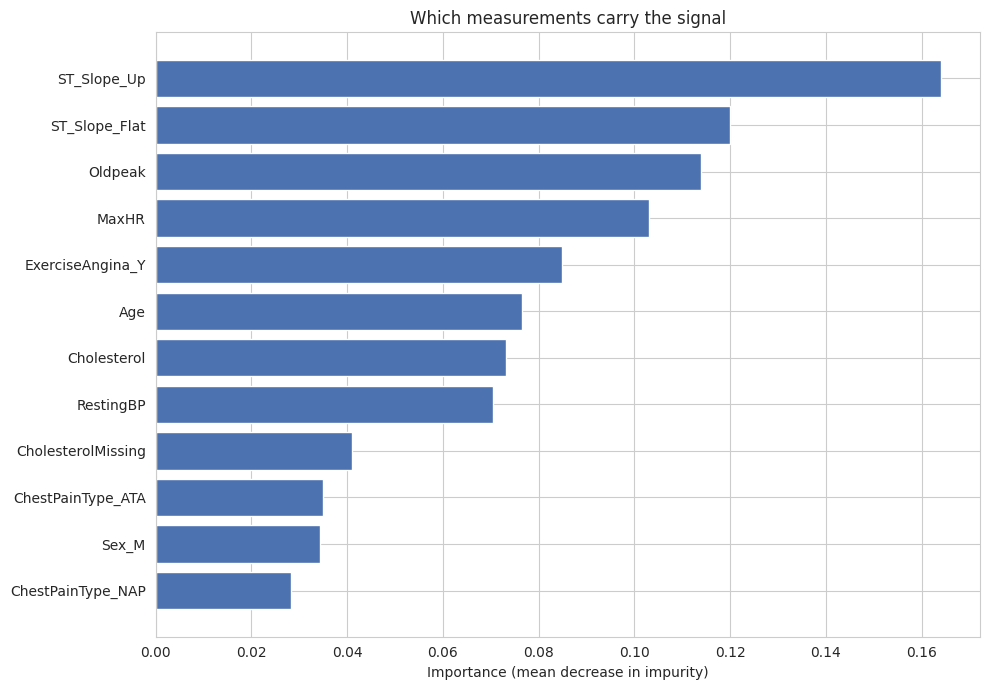

In [22]:
rf = candidates['Random forest'].named_steps['model']
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

print('Random forest feature importances:')
print(importances.round(4).to_string())

plt.figure(figsize=(10, 7))
top = importances.head(12).sort_values()
plt.barh(top.index, top.values, color='#4C72B0')
plt.xlabel('Importance (mean decrease in impurity)')
plt.title('Which measurements carry the signal')
plt.tight_layout()
plt.show()

## 9. Tuning the decision threshold

Every model above predicts the positive class at a probability of 0.50, which is an arbitrary default rather than a clinical decision. Lowering the threshold catches more sick patients at the cost of more false alarms. The table makes that trade explicit so it can be chosen deliberately instead of inherited.

In [23]:
thresholds = [0.6, 0.5, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1]
rows = []
for t in thresholds:
    pred_t = (y_proba >= t).astype(int)
    cmx = confusion_matrix(y_test, pred_t)
    rows.append({
        'threshold': t,
        'accuracy': round(accuracy_score(y_test, pred_t), 4),
        'precision': round(precision_score(y_test, pred_t, zero_division=0), 4),
        'recall': round(recall_score(y_test, pred_t), 4),
        'f1': round(f1_score(y_test, pred_t, zero_division=0), 4),
        'missed_cases': int(cmx[1, 0]),
        'false_alarms': int(cmx[0, 1])
    })

thresh_tbl = pd.DataFrame(rows).set_index('threshold')
print('Tuned KNN at different decision thresholds:')
print(thresh_tbl.to_string())

Tuned KNN at different decision thresholds:
           accuracy  precision  recall      f1  missed_cases  false_alarms
threshold                                                                 
0.60         0.9130     0.9388  0.9020  0.9200            10             6
0.50         0.9076     0.9126  0.9216  0.9171             8             9
0.40         0.8859     0.8649  0.9412  0.9014             6            15
0.35         0.8859     0.8584  0.9510  0.9023             5            16
0.30         0.8696     0.8362  0.9510  0.8899             5            19
0.25         0.8315     0.7886  0.9510  0.8622             5            26
0.20         0.8098     0.7557  0.9706  0.8498             3            32
0.15         0.7935     0.7388  0.9706  0.8390             3            35
0.10         0.7880     0.7299  0.9804  0.8368             2            37


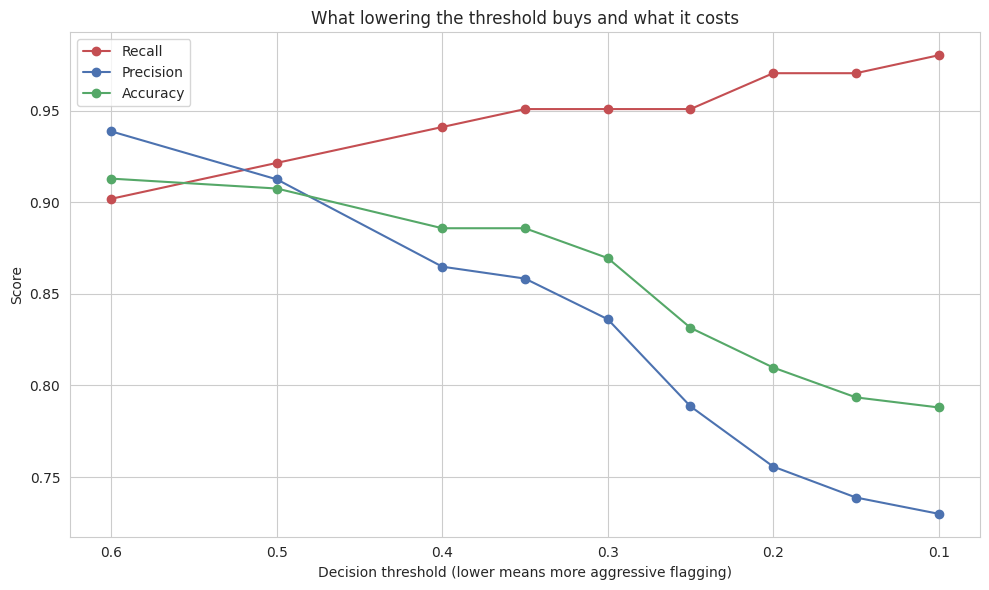

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(thresh_tbl.index, thresh_tbl['recall'], marker='o', label='Recall', color='#C44E52')
ax.plot(thresh_tbl.index, thresh_tbl['precision'], marker='o', label='Precision', color='#4C72B0')
ax.plot(thresh_tbl.index, thresh_tbl['accuracy'], marker='o', label='Accuracy', color='#55A868')
ax.invert_xaxis()
ax.set_xlabel('Decision threshold (lower means more aggressive flagging)')
ax.set_ylabel('Score')
ax.set_title('What lowering the threshold buys and what it costs')
ax.legend()
plt.tight_layout()
plt.show()

## 10. Conclusions

### Model performance

The tuned KNN uses **k=17, Manhattan distance (p=1), distance-weighted neighbours**, selected from 64 configurations by 5-fold cross-validated recall. Tuning lifted cross-validated recall from 0.8818 (untuned k=5) to 0.9163.

On the 184-patient held-out test set:

| Metric | Value |
|---|---|
| Accuracy | 0.9076 |
| Precision | 0.9126 |
| **Recall** | **0.9216** |
| F1 | 0.9171 |
| ROC AUC | 0.9449 |
| Majority-class baseline accuracy | 0.5543 |

Confusion matrix: 73 true negatives, 9 false positives, **8 false negatives**, 94 true positives. Eight patients with heart disease were classified as healthy.

### Model comparison

| Model | Accuracy | Precision | Recall | ROC AUC | Missed cases |
|---|---|---|---|---|---|
| KNN (tuned) | 0.9076 | 0.9126 | 0.9216 | 0.9449 | 8 |
| Logistic regression | 0.8913 | 0.8868 | 0.9216 | 0.9327 | 8 |
| Random forest | 0.8804 | 0.8846 | 0.9020 | 0.9371 | 10 |

KNN edges the other two on every metric, which is a slightly surprising result: a distance-based method beating a random forest on tabular data usually signals that the decision boundary is fairly smooth once the features are scaled.

The more useful observation is that **logistic regression ties KNN exactly on recall, missing the same eight patients**, at a cost of 1.6 points of accuracy. On a tie in the metric that matters clinically, logistic regression is arguably the better deployment choice: it yields a coefficient per predictor that a clinician can inspect and challenge, whereas KNN can only say that seventeen similar patients were mostly sick. Accuracy is the wrong tiebreaker for a screening tool, and interpretability is a real feature rather than a consolation prize.

### The data quality finding, which mattered more than the model choice

`isnull()` reported zero missing values. In fact **172 patients (18.7%) had cholesterol recorded as 0** and one had a resting blood pressure of 0, both physiologically impossible and both clearly absent measurements written as zeros.

The missingness is strongly informative:

| | Heart disease rate | n |
|---|---|---|
| Cholesterol present | 47.7% | 746 |
| Cholesterol recorded as 0 | **88.4%** | 172 |
| Overall | 55.3% | 918 |

A patient whose cholesterol was never recorded is nearly twice as likely to have heart disease. Both reflex responses would have been wrong: dropping those rows discards 18.7% of the data along with a strong signal, and imputing them silently buries that signal in the median. Replacing the zeros with `NaN` for honest imputation **and** retaining a `CholesterolMissing` flag keeps both. The random forest ranked that flag 9th of 17 features at an importance of 0.0409, so the model does use it.

Why the signal exists at all is a question the data cannot answer. The plausible reading is a recording artefact at one of the contributing hospitals rather than anything clinical, which is a caution against treating it as a finding about patients.

### What carries the signal

| Feature | Importance |
|---|---|
| ST_Slope_Up | 0.1640 |
| ST_Slope_Flat | 0.1199 |
| Oldpeak | 0.1139 |
| MaxHR | 0.1031 |
| ExerciseAngina_Y | 0.0850 |
| Age | 0.0766 |

The top five are all derived from the exercise stress test: the slope of the ST segment, ST depression, maximum heart rate achieved, and exercise-induced angina. Resting blood pressure and cholesterol, the measurements taken at rest, rank below them. The exercise test is doing the diagnostic work, which is consistent with the clinical literature and is a sanity check that the model is keying on something real.

### The threshold is a policy choice, not a default

| Threshold | Recall | Accuracy | Missed cases | False alarms |
|---|---|---|---|---|
| 0.60 | 0.9020 | 0.9130 | 10 | 6 |
| **0.50** (default) | 0.9216 | 0.9076 | 8 | 9 |
| 0.35 | 0.9510 | 0.8859 | 5 | 16 |
| 0.20 | 0.9706 | 0.8098 | 3 | 32 |
| 0.10 | 0.9804 | 0.7880 | 2 | 37 |

Moving from 0.50 to 0.35 catches three more sick patients for seven more false alarms and costs 2.2 points of accuracy. Going all the way to 0.10 catches six more than the default at the price of 28 extra false alarms. For a screening tool feeding into further testing rather than into treatment, something near 0.35 is defensible. That is a clinical and operational judgement, not a modelling one, and the point of the table is to hand it to whoever should be making it.

### Limitations

- **The threshold table is computed on the test set.** Reading a threshold off it and then reporting the same test metrics would be a mild form of selection leakage. Adopted for real, the threshold should be chosen on a validation split or by cross-validation, and the number above treated as illustrative.
- **184 test patients is a small test set.** A single extra false negative moves recall by about one point, so the gap between KNN and logistic regression (zero, on recall) is well inside the noise. Repeated or nested cross-validation would give an honest variance estimate; the single split here does not.
- **Median imputation across 18.7% of cholesterol values compresses that feature's variance** and pulls those patients toward the centre. The missingness flag mitigates this but does not repair the measurement.
- **No calibration check was run.** The thresholds above assume the predicted probabilities mean roughly what they say, and KNN probabilities from 17 neighbours are coarse by construction, taking only 18 distinct values under uniform weighting.
- **This is the pooled UCI heart dataset, assembled from several hospitals in the late 1980s.** It does not represent current populations, current diagnostic practice, or any single clinical setting, so none of these numbers should be read as an estimate of real-world screening performance.
- **Nothing here is a diagnostic tool.** It is a classification exercise on a public teaching dataset.